In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from mpl_toolkits.mplot3d import Axes3D

In [3]:
wine = load_wine()

winedata = pd.DataFrame(wine.data, columns = wine.feature_names)
winedata.head()


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


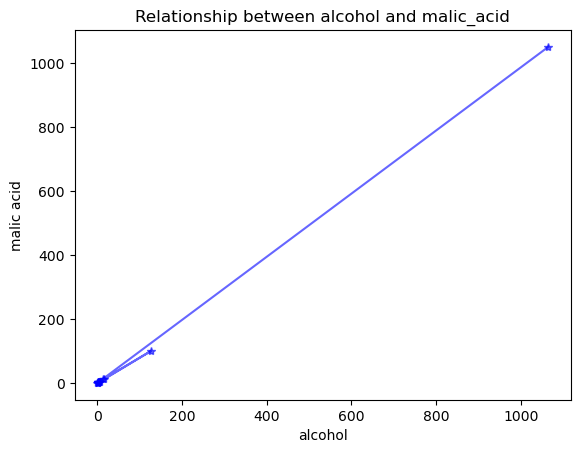

In [23]:
# Plot a line graph showing the relationship between alcohol and malic_acid using matplotlib.pyplot.
plt.plot(winedata.iloc[0], winedata.iloc[1], marker ='*', c='blue', alpha=0.6)
plt.xlabel('alcohol')
plt.ylabel('malic acid')
plt.title("Relationship between alcohol and malic_acid")
plt.show()
#plt.tightlayout()

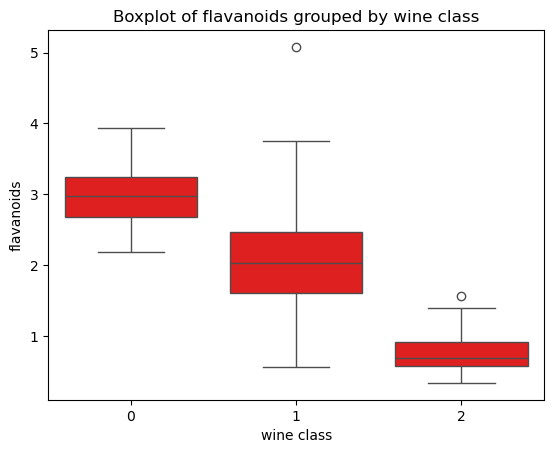

In [44]:
#  Create a boxplot of flavanoids grouped by wine class (target) using seaborn.boxplot()
winedata['wine class']= wine.target
#winedata.groupby('wine class')['flavanoids']
sns.boxplot(x='wine class', y='flavanoids', data =winedata,  color='red')
plt.title('Boxplot of flavanoids grouped by wine class')
plt.show()

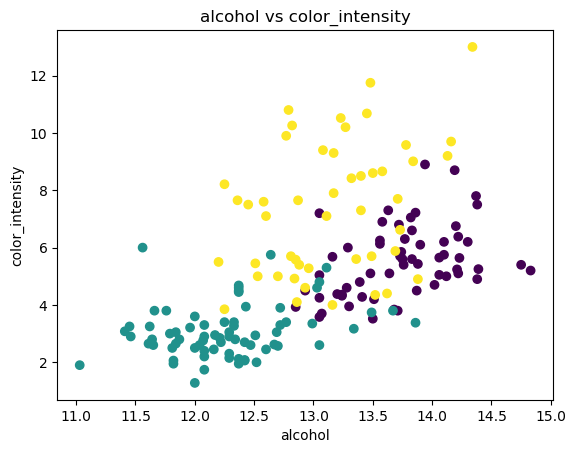

In [43]:
# Draw a 2D scatterplot for alcohol vs color_intensity, with color coding based on wine class.

plt.scatter(winedata['alcohol'], winedata['color_intensity'], c=winedata['wine class'])
plt.xlabel('alcohol')
plt.ylabel('color_intensity')
plt.title('alcohol vs color_intensity')
plt.show()

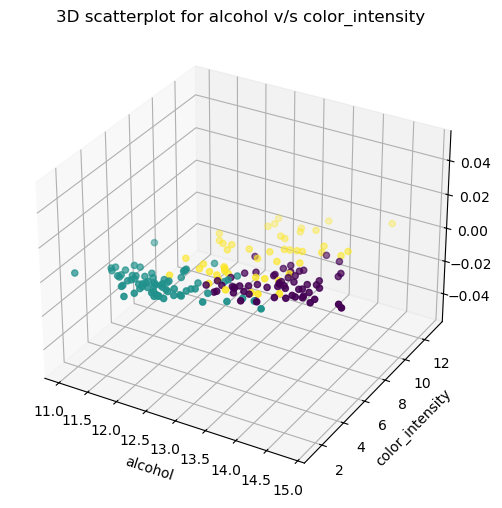

In [46]:
# Create a 3D scatterplot using alcohol, color_intensity, and hue as axes. Use
#different colors for each wine class. Use matplotlib's 3D plotting tools.

fig= plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection= '3d')
ax.scatter(winedata['alcohol'], winedata['color_intensity'], c=winedata['wine class'])
ax.set_xlabel(wine.feature_names[0])
ax.set_ylabel(wine.feature_names[9])
plt.title('3D scatterplot for alcohol v/s color_intensity')
plt.show()

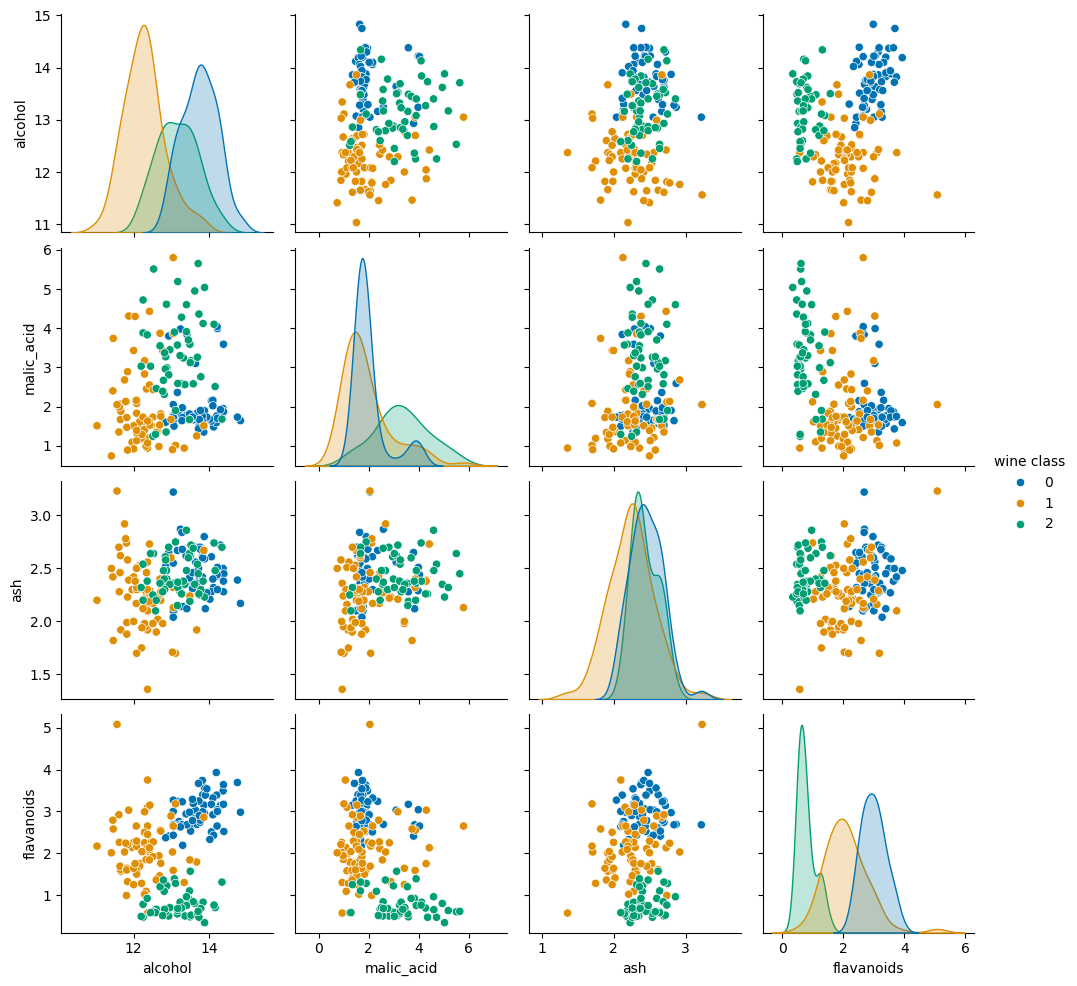

In [56]:
# Select any 4 numerical columns from the dataset and create a seaborn.pairplot() with hue='target'.
winedata['wine class']= wine.target
num_cols= ['alcohol', 'malic_acid', 'ash', 'flavanoids']
sns.pairplot(winedata[num_cols+ ['wine class']], hue='wine class', palette='colorblind')
plt.show()

In [ ]:
# Briefly explain two limitations of using pair plots for high-dimensional datasets
#such as the Wine dataset. Suggest an alternative for each limitation.

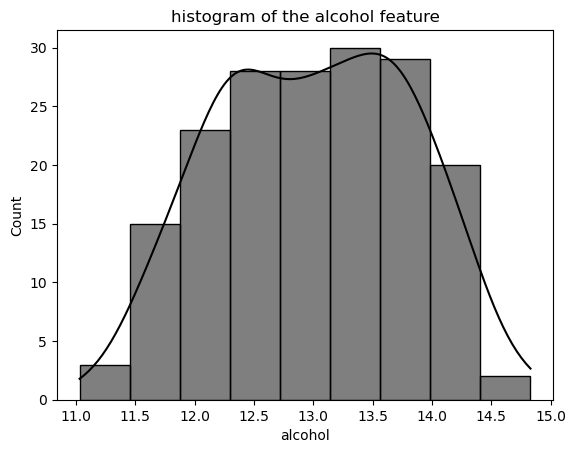

In [58]:
# Plot a histogram of the alcohol feature. Overlay the PDF (Probability Density Function) using Seaborn’s kdeplot

sns.histplot(winedata[wine.feature_names[0]], kde=True, fill=True, color= 'black')
plt.title('histogram of the alcohol feature')
plt.show()

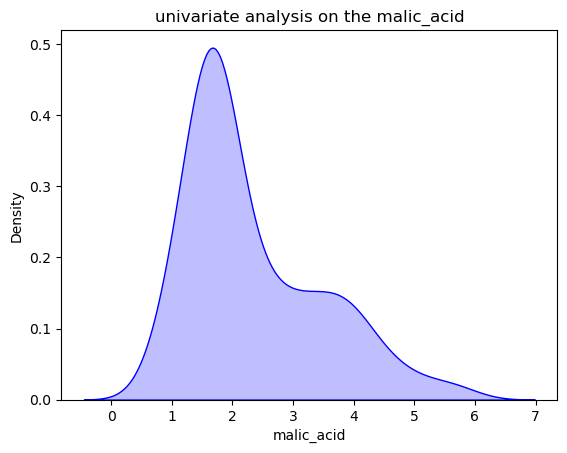

In [59]:
# Perform a univariate analysis on the malic_acid feature using its PDF plot.
# Comment on its distribution shape

sns.kdeplot(winedata[wine.feature_names[1]], fill=True, color='blue')
plt.title('univariate analysis on the malic_acid')
plt.show()

## The distribution is right skewed

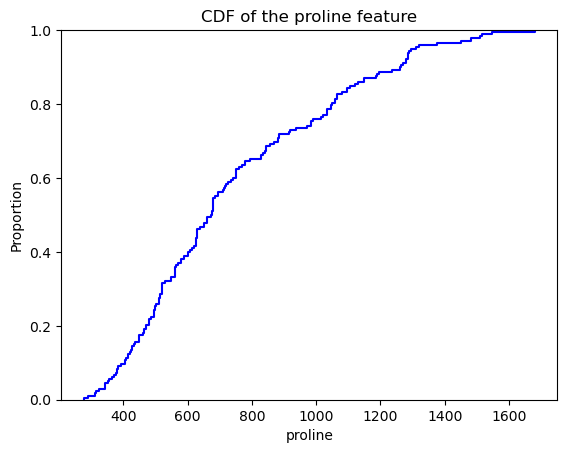

percentage of samples of proline less than 800 is :65.1685393258427


In [66]:
# Compute and plot the CDF of the proline feature. What percentage of samples
#have proline less than 800

sns.ecdfplot(winedata[wine.feature_names[-1]], color='blue')
plt.title('CDF of the proline feature')
plt.show()

percent_prop = (winedata[wine.feature_names[-1]]<800).sum()*100/len(winedata)
print(f'percentage of samples of proline less than 800 is :{percent_prop}')